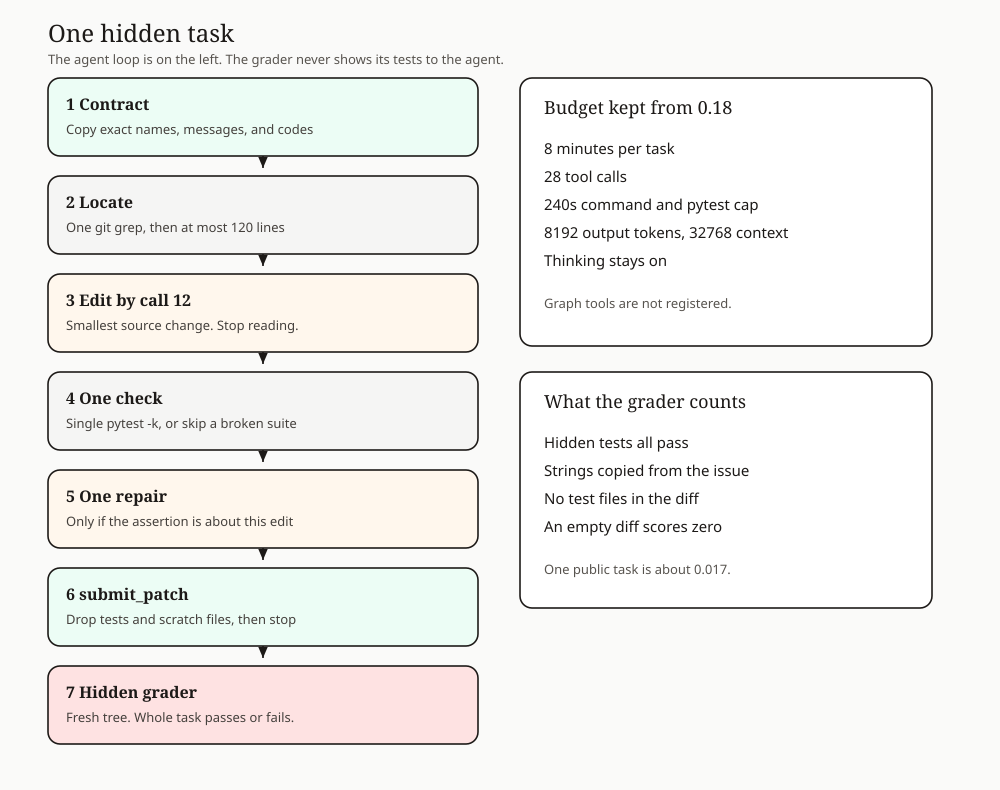

In [1]:
from pathlib import Path

def workflow_svg() -> str:
    """Stdlib flowchart of one graded attempt. No extra packages."""
    def box(x, y, w, h, title, body, fill):
        return (
            f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="12" '
            f'fill="{fill}" stroke="#1c1917" stroke-width="1.6"/>'
            f'<text x="{x + 18}" y="{y + 32}" font-family="Georgia, serif" '
            f'font-size="16" font-weight="700" fill="#1c1917">{title}</text>'
            f'<text x="{x + 18}" y="{y + 56}" font-family="ui-sans-serif, sans-serif" '
            f'font-size="13" fill="#44403c">{body}</text>'
        )

    def arrow(x, y1, y2):
        return (
            f'<line x1="{x}" y1="{y1}" x2="{x}" y2="{y2}" stroke="#1c1917" '
            f'stroke-width="1.6" marker-end="url(#arrow)"/>'
        )

    steps = [
        (78, "1  Contract", "Copy exact names, messages, and codes", "#ecfdf5"),
        (176, "2  Locate", "One git grep, then at most 120 lines", "#f5f5f4"),
        (274, "3  Edit by call 12", "Smallest source change. Stop reading.", "#fff7ed"),
        (372, "4  One check", "Single pytest -k, or skip a broken suite", "#f5f5f4"),
        (470, "5  One repair", "Only if the assertion is about this edit", "#fff7ed"),
        (568, "6  submit_patch", "Drop tests and scratch files, then stop", "#ecfdf5"),
        (666, "7  Hidden grader", "Fresh tree. Whole task passes or fails.", "#fee2e2"),
    ]
    x, w, h = 48, 430, 78
    parts = [
        '<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="790" viewBox="0 0 1000 790">',
        '<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="3" orient="auto">',
        '<path d="M0,0 L7,3 L0,6 Z" fill="#1c1917"/></marker></defs>',
        '<rect width="1000" height="790" fill="#fafaf9"/>',
        '<text x="48" y="42" font-family="Georgia, serif" font-size="24" fill="#1c1917">One hidden task</text>',
        '<text x="48" y="64" font-family="ui-sans-serif, sans-serif" font-size="13" fill="#57534e">The agent loop is on the left. The grader never shows its tests to the agent.</text>',
    ]
    for i, (y, title, body, fill) in enumerate(steps):
        parts.append(box(x, y, w, h, title, body, fill))
        if i:
            parts.append(arrow(x + w / 2, steps[i - 1][0] + h, y - 8))
    parts.append(
        '<rect x="520" y="78" width="412" height="268" rx="12" fill="#ffffff" stroke="#1c1917" stroke-width="1.6"/>'
        '<text x="544" y="114" font-family="Georgia, serif" font-size="18" fill="#1c1917">Budget kept from 0.18</text>'
        '<text x="544" y="154" font-family="ui-sans-serif, sans-serif" font-size="15" fill="#1c1917">8 minutes per task</text>'
        '<text x="544" y="182" font-family="ui-sans-serif, sans-serif" font-size="15" fill="#1c1917">28 tool calls</text>'
        '<text x="544" y="210" font-family="ui-sans-serif, sans-serif" font-size="15" fill="#1c1917">240s command and pytest cap</text>'
        '<text x="544" y="238" font-family="ui-sans-serif, sans-serif" font-size="15" fill="#1c1917">8192 output tokens, 32768 context</text>'
        '<text x="544" y="266" font-family="ui-sans-serif, sans-serif" font-size="15" fill="#1c1917">Thinking stays on</text>'
        '<text x="544" y="308" font-family="ui-sans-serif, sans-serif" font-size="13" fill="#57534e">Graph tools are not registered.</text>'
    )
    parts.append(
        '<rect x="520" y="372" width="412" height="236" rx="12" fill="#ffffff" stroke="#1c1917" stroke-width="1.6"/>'
        '<text x="544" y="408" font-family="Georgia, serif" font-size="18" fill="#1c1917">What the grader counts</text>'
        '<text x="544" y="448" font-family="ui-sans-serif, sans-serif" font-size="15" fill="#1c1917">Hidden tests all pass</text>'
        '<text x="544" y="476" font-family="ui-sans-serif, sans-serif" font-size="15" fill="#1c1917">Strings copied from the issue</text>'
        '<text x="544" y="504" font-family="ui-sans-serif, sans-serif" font-size="15" fill="#1c1917">No test files in the diff</text>'
        '<text x="544" y="532" font-family="ui-sans-serif, sans-serif" font-size="15" fill="#1c1917">An empty diff scores zero</text>'
        '<text x="544" y="574" font-family="ui-sans-serif, sans-serif" font-size="13" fill="#57534e">One public task is about 0.017.</text>'
    )
    parts.append("</svg>")
    return "".join(parts)


svg = workflow_svg()
out = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
(out / "workflow.svg").write_text(svg, encoding="utf-8")
try:
    from IPython.display import SVG, display
    display(SVG(data=svg))
except Exception:
    print(f"Wrote {out / 'workflow.svg'}")


In [2]:
import hashlib
import zipfile
from pathlib import Path

FILES = {
    "agent.yaml": """name: swe_agent
model: gemma-4-31b-it-qat-w4a16-ct
instruction: !include prompts/system.md
tools:
  - run_command
  - read_file
  - edit_file
  - write_file
  - get_status
  - submit_patch
generate_content_config: !include configs/sampling.yaml
""",
    "configs/sampling.yaml": """temperature: 0.2
top_p: 0.95
max_output_tokens: 8192
thinking_config:
  thinking_budget: 4096
  include_thoughts: true
""",
    "eval_config.yaml": """evaluation:
  timeout_seconds: 240
  max_tool_calls: 28
  max_time_minutes: 8
  max_turns: 80
""",
    "prompts/system.md": """You are an expert autonomous software engineer. Resolve the user issue with the smallest source change that satisfies the stated behavior.

The hidden grader applies your git diff to a fresh repository and runs its own tests. It never sees your reasoning. An empty diff scores zero. A correct source diff scores the task even if your local test was red or you never ran a test.

## Budget
You have 28 tool calls and 8 minutes. When either limit hits, the working tree is graded as it is. An edit made in time counts even if you do not reach submit_patch. Finish as soon as the edit is in so later tasks still have time.

## 1. Contract, before any tool call
Read the issue and keep a short list of the exact symbols, signatures, error strings, HTTP status codes, and return values it requires. Copy them character for character. The grader checks those strings exactly.

## 2. Locate in a few reads
- Search once with `git grep -n "SPECIFIC_TOKEN" -- '*.py' | head -20`. Use the most specific identifier or error string from the issue.
- Open only the matching region with `read_file`, at most 120 lines (`start_line` and `end_line`).
- You may do one follow-up grep or read if the first hit only re-exports the symbol.
- Do not page through unrelated files. Do not read a whole file when a range will do.

## 3. Edit by tool call 12
- By your 12th tool call a source file must already be edited. If it is not, edit the most likely function immediately. Runs that are still only reading after 12 calls almost never succeed.
- Prefer `edit_file`. `old_string` must match the file exactly, including indentation. Change the smallest span that implements the contract.
- FastAPI documentation tasks: edit the executable example under `docs_src/`.
- Do not reformat or refactor unrelated code.
- Create a new file only when the issue explicitly requires a new module. Never create or edit `test_*.py`, `*_test.py`, anything under `tests/`, `pytest.ini`, or `conftest.py`.
- Any scratch script goes in `/tmp` through `run_command`. Never write scratch files into `/workspace`. Files left in the repository become part of the diff and fail grading.

## 4. One check, one repair, then submit
- After the edit, run at most one focused check: `pytest tests/test_file.py -k test_name -q` or `python -c "..."`.
- Never run bare `pytest`, `pytest .`, or `python -m unittest discover`.
- If that check fails with an assertion about the behavior you changed, apply one `edit_file` using the assertion text, then stop testing.
- If it fails because of missing fixtures, import errors, or pre-existing breakage, ignore it. Do not repair tests and do not install packages.
- Call `submit_patch` after that, even when the local check is red or you skipped it. A local green test is not the grader.
- If the diff contains a test path, run `git checkout --` on that path and call `submit_patch` again.
- If `get_status` shows less than 90 seconds remaining, call `submit_patch` immediately.

## Never
- Conclude that the code is already correct. Every task needs a source modification and a non-empty patch.
- Search outside `/workspace` (`/usr`, `/wheels`, `/opt`). Dependencies are already installed.
- Spend calls on broad exploration after the first edit.
""",
}

EXPECTED = {
    "agent.yaml",
    "configs/sampling.yaml",
    "eval_config.yaml",
    "prompts/system.md",
}
ALLOWED_EXT = {".yaml", ".yml", ".md", ".json", ".safetensors", ".txt", ".py"}
REQUIRED_TOOLS = [
    "run_command",
    "read_file",
    "edit_file",
    "write_file",
    "get_status",
    "submit_patch",
]
FORBIDDEN_TOOLS = ["get_code_neighbors", "search_similar_code", "get_code_subgraph"]


def check_archive(files: dict) -> None:
    if set(files) != EXPECTED:
        raise SystemExit(f"Unexpected archive contents: {sorted(files)}")
    agent = files["agent.yaml"]
    if "model: gemma-4-31b-it-qat-w4a16-ct" not in agent:
        raise SystemExit("The only permitted base model is missing.")
    if "instruction: !include prompts/system.md" not in agent:
        raise SystemExit("agent.yaml must include prompts/system.md.")
    if "generate_content_config: !include configs/sampling.yaml" not in agent:
        raise SystemExit("agent.yaml must include configs/sampling.yaml.")
    for tool in REQUIRED_TOOLS:
        if f"- {tool}\n" not in agent:
            raise SystemExit(f"Missing tool: {tool}")
    for tool in FORBIDDEN_TOOLS:
        if tool in agent:
            raise SystemExit(f"Graph tool still registered: {tool}")
    sampling = files["configs/sampling.yaml"]
    for needle in ("temperature: 0.2\n", "top_p: 0.95\n", "max_output_tokens: 8192\n", "include_thoughts: true\n"):
        if needle not in sampling:
            raise SystemExit(f"Sampling drift: {needle!r}")
    evaluation = files["eval_config.yaml"]
    for needle in (
        "timeout_seconds: 240\n",
        "max_tool_calls: 28\n",
        "max_time_minutes: 8\n",
        "max_turns: 80\n",
    ):
        if needle not in evaluation:
            raise SystemExit(f"Budget drift: {needle!r}")
    prompt = files["prompts/system.md"]
    for needle in (
        "character for character",
        "12th tool call",
        "submit_patch",
        "/tmp",
        "docs_src/",
        "local green test is not the grader",
        "less than 90 seconds",
    ):
        if needle not in prompt:
            raise SystemExit(f"Prompt is missing the rule: {needle}")
    if "search_similar_code" in prompt or "get_code_neighbors" in prompt:
        raise SystemExit("Prompt still mentions a graph tool by name.")
    unpacked = sum(len(text.encode()) for text in files.values())
    if unpacked >= 3 * 1024**3:
        raise SystemExit("Unpacked submission must stay under 3 GiB.")


check_archive(FILES)

out = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
archive = out / "submission.zip"
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for name in sorted(FILES):
        ext = Path(name).suffix.lower()
        if ext not in ALLOWED_EXT:
            raise SystemExit(f"Disallowed extension: {name}")
        zf.writestr(name, FILES[name])

with zipfile.ZipFile(archive) as zf:
    names = set(zf.namelist())
    if zf.testzip() is not None or names != EXPECTED or "agent.yaml" not in names:
        raise SystemExit("Archive verification failed.")
    bad_root = [n for n in names if n.startswith("/") or n.startswith("..") or n.split("/")[0] == "agent"]
    if bad_root:
        raise SystemExit(f"agent.yaml must sit at the archive root, found {bad_root}")

digest = hashlib.sha256(archive.read_bytes()).hexdigest()
print(f"Wrote {archive} ({archive.stat().st_size} bytes)")
print(f"SHA256 {digest}")
print("Files:")
for name in sorted(FILES):
    print(f"  {name:28} {len(FILES[name].encode()):5} bytes")
print("Budget: 8 min, 28 tool calls, 240 s command/pytest timeout, 80 turns")
print("Model:  gemma-4-31b-it-qat-w4a16-ct")
print("Submit this notebook output. Kaggle scores submission.zip, not this cell's printout.")


Wrote /kaggle/working/submission.zip (2397 bytes)
SHA256 1ada4b629ed4db2e1d941af4d3056f6d3f81c977a56a6ed0f1de86eb1a94437d
Files:
  agent.yaml                     245 bytes
  configs/sampling.yaml          119 bytes
  eval_config.yaml                94 bytes
  prompts/system.md             3240 bytes
Budget: 8 min, 28 tool calls, 240 s command/pytest timeout, 80 turns
Model:  gemma-4-31b-it-qat-w4a16-ct
Submit this notebook output. Kaggle scores submission.zip, not this cell's printout.
